<a href="https://colab.research.google.com/github/Navi-E/NLP_Task1/blob/main/task3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install numpy nltk spacy tensorflow

In [5]:
import sys
import numpy as np
import nltk
import spacy

from nltk.tokenize import word_tokenize
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [6]:
try:
    nltk.data.find("tokenizers/punkt")
except LookupError:
    nltk.download("punkt", quiet=True)

# For environments that require the additional NLTK resource
try:
    nltk.data.find("tokenizers/punkt_tab")
except LookupError:
    nltk.download("punkt_tab", quiet=True)

In [7]:
try:
    nlp = spacy.load("en_core_web_sm")
except OSError as error:
    raise RuntimeError(
        "Install the spaCy model with: "
        "python -m spacy download en_core_web_sm"
    ) from error

In [8]:
corpus = """One disadvantage of using 'Best Of' sampling is that it may lead to limited exploration of the model's knowledge and creativity. By focusing on the most probable next words, the model might generate responses that are safe and conventional, potentially missing out on more diverse and innovative outputs. The lack of exploration could result in repetitive or less imaginative responses, especially in situations where novel and unconventional ideas are desired. To address this limitation, other sampling strategies like temperature-based sampling or top-p (nucleus) sampling can be employed to introduce more randomness and encourage the model to explore a broader range of possibilities. However, it's essential to carefully balance exploration and exploitation based on the specific requirements of the task or application."""

In [9]:
tokens = word_tokenize(corpus)

print("Original Tokens:")
print(tokens)

Original Tokens:
['One', 'disadvantage', 'of', 'using', "'Best", 'Of', "'", 'sampling', 'is', 'that', 'it', 'may', 'lead', 'to', 'limited', 'exploration', 'of', 'the', 'model', "'s", 'knowledge', 'and', 'creativity', '.', 'By', 'focusing', 'on', 'the', 'most', 'probable', 'next', 'words', ',', 'the', 'model', 'might', 'generate', 'responses', 'that', 'are', 'safe', 'and', 'conventional', ',', 'potentially', 'missing', 'out', 'on', 'more', 'diverse', 'and', 'innovative', 'outputs', '.', 'The', 'lack', 'of', 'exploration', 'could', 'result', 'in', 'repetitive', 'or', 'less', 'imaginative', 'responses', ',', 'especially', 'in', 'situations', 'where', 'novel', 'and', 'unconventional', 'ideas', 'are', 'desired', '.', 'To', 'address', 'this', 'limitation', ',', 'other', 'sampling', 'strategies', 'like', 'temperature-based', 'sampling', 'or', 'top-p', '(', 'nucleus', ')', 'sampling', 'can', 'be', 'employed', 'to', 'introduce', 'more', 'randomness', 'and', 'encourage', 'the', 'model', 'to', 'e

In [10]:
lemmatized_tokens = [
    token.lemma_ for token in nlp(corpus)
]

print("Lemmatized Tokens:")
print(lemmatized_tokens)

Lemmatized Tokens:
['one', 'disadvantage', 'of', 'use', "'", 'good', 'of', "'", 'sampling', 'be', 'that', 'it', 'may', 'lead', 'to', 'limited', 'exploration', 'of', 'the', 'model', "'s", 'knowledge', 'and', 'creativity', '.', 'by', 'focus', 'on', 'the', 'most', 'probable', 'next', 'word', ',', 'the', 'model', 'might', 'generate', 'response', 'that', 'be', 'safe', 'and', 'conventional', ',', 'potentially', 'miss', 'out', 'on', 'more', 'diverse', 'and', 'innovative', 'output', '.', 'the', 'lack', 'of', 'exploration', 'could', 'result', 'in', 'repetitive', 'or', 'less', 'imaginative', 'response', ',', 'especially', 'in', 'situation', 'where', 'novel', 'and', 'unconventional', 'idea', 'be', 'desire', '.', 'to', 'address', 'this', 'limitation', ',', 'other', 'sample', 'strategy', 'like', 'temperature', '-', 'base', 'sampling', 'or', 'top', '-', 'p', '(', 'nucleus', ')', 'sampling', 'can', 'be', 'employ', 'to', 'introduce', 'more', 'randomness', 'and', 'encourage', 'the', 'model', 'to', 'exp

In [11]:
all_tokens = tokens + lemmatized_tokens

print("Total number of tokens:", len(all_tokens))
print("Combined Tokens:")
print(all_tokens)

Total number of tokens: 277
Combined Tokens:
['One', 'disadvantage', 'of', 'using', "'Best", 'Of', "'", 'sampling', 'is', 'that', 'it', 'may', 'lead', 'to', 'limited', 'exploration', 'of', 'the', 'model', "'s", 'knowledge', 'and', 'creativity', '.', 'By', 'focusing', 'on', 'the', 'most', 'probable', 'next', 'words', ',', 'the', 'model', 'might', 'generate', 'responses', 'that', 'are', 'safe', 'and', 'conventional', ',', 'potentially', 'missing', 'out', 'on', 'more', 'diverse', 'and', 'innovative', 'outputs', '.', 'The', 'lack', 'of', 'exploration', 'could', 'result', 'in', 'repetitive', 'or', 'less', 'imaginative', 'responses', ',', 'especially', 'in', 'situations', 'where', 'novel', 'and', 'unconventional', 'ideas', 'are', 'desired', '.', 'To', 'address', 'this', 'limitation', ',', 'other', 'sampling', 'strategies', 'like', 'temperature-based', 'sampling', 'or', 'top-p', '(', 'nucleus', ')', 'sampling', 'can', 'be', 'employed', 'to', 'introduce', 'more', 'randomness', 'and', 'encourag

In [12]:
tokenizer = Tokenizer()

tokenizer.fit_on_texts([" ".join(all_tokens)])

total_words = len(tokenizer.word_index) + 1

print("Total words in vocabulary:", total_words)

Total words in vocabulary: 105


In [13]:
token_list = tokenizer.texts_to_sequences(
    [" ".join(all_tokens)]
)[0]

input_sequences = []

for i in range(1, len(token_list)):
    input_sequences.append(token_list[:i + 1])

print("Number of input sequences:", len(input_sequences))
print("First 5 sequences:")
print(input_sequences[:5])

Number of input sequences: 252
First 5 sequences:
[[17, 18], [17, 18, 2], [17, 18, 2, 75], [17, 18, 2, 75, 76], [17, 18, 2, 75, 76, 2]]


In [14]:
max_sequence_length = max(
    len(seq) for seq in input_sequences
)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_length,
    padding="pre"
)

print("Maximum sequence length:", max_sequence_length)
print("Padded sequences shape:", input_sequences.shape)

Maximum sequence length: 253
Padded sequences shape: (252, 253)


In [15]:
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (252, 252)
y shape: (252,)


In [16]:
model = Sequential()

model.add(
    Embedding(
        total_words,
        100,
        input_length=max_sequence_length - 1
    )
)

model.add(LSTM(100))

model.add(
    Dense(total_words, activation="softmax")
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
history = model.fit(
    X,
    y,
    epochs=10,
    verbose=1
)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 234ms/step - accuracy: 0.0278 - loss: 4.6503
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 542ms/step - accuracy: 0.1071 - loss: 4.6200
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 379ms/step - accuracy: 0.0556 - loss: 4.5015
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 196ms/step - accuracy: 0.0556 - loss: 4.4166
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 156ms/step - accuracy: 0.0556 - loss: 4.3765
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step - accuracy: 0.0873 - loss: 4.3436
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - accuracy: 0.0794 - loss: 4.3052
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 284ms/step - accuracy: 0.0754 - loss: 4.2473
Epoch 9/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.0833 - loss: 4.1564
Epoch 10/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step - accuracy: 0.1310 - loss: 4.0312


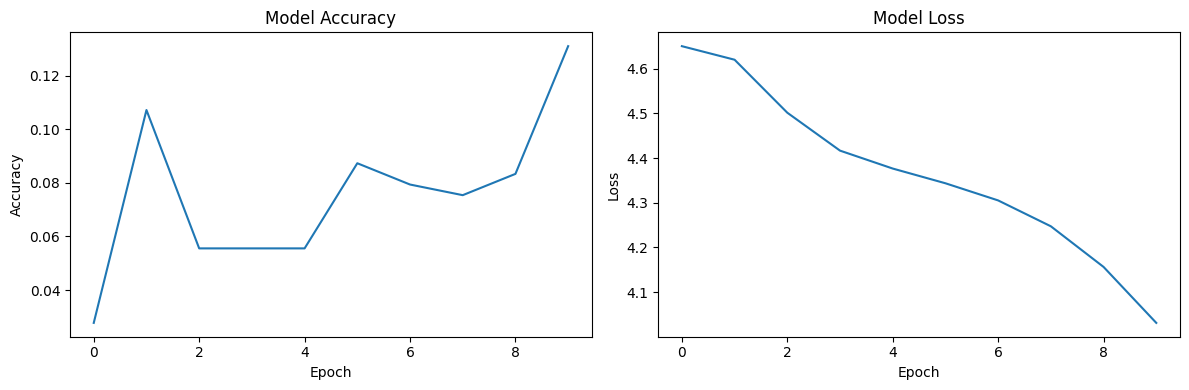

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()